In [50]:
!pip install -q langchain langchain-groq

In [51]:
import os
from google.colab import userdata
os.environ["GROQ_API_KEY"] = userdata.get("GROQ_API_KEY")
from langchain_groq import ChatGroq
llm = ChatGroq(model="openai/gpt-oss-120b", temperature=0.3)

In [52]:
from typing import Literal
from pydantic import BaseModel, Field

class Intent(BaseModel):
    intent: Literal["order", "faq", "other"] = Field(
        description="order = wants to buy or book; faq = asks about prices, timings or policies; other = anything else")
classifier = llm.with_structured_output(Intent)
def handle(message: str) -> str:
    intent = classifier.invoke(message).intent
    if intent == "order":
        return take_order(message)
    elif intent == "faq":
        return answer_faq(message)
    else:
        return "I can help with cakes, orders and our policies. What would you like?"

In [53]:
from typing_extensions import TypedDict
class BakeryState(TypedDict):
    message: str     # what the customer wrote
    intent: str      # filled in by the classify step
    reply: str       # filled in by whichever path handles it

In [54]:
from langgraph.graph import StateGraph, START, END
def classify(state: BakeryState) -> dict:
    return {"intent": classifier.invoke(state["message"]).intent}
def answer_faq(state: BakeryState) -> dict:
    return {"reply": "…answer from search_faq…"}

builder = StateGraph(BakeryState)
builder.add_node("classify", classify)
builder.add_node("faq", answer_faq)
builder.add_edge(START, "classify")
builder.add_edge("classify", "faq")
builder.add_edge("faq", END)
graph = builder.compile()
result = graph.invoke({"message": "Do you deliver?"})
print(result["reply"])

…answer from search_faq…


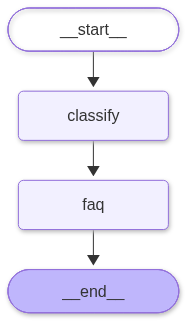

{'classify': {'intent': 'faq'}}
{'faq': {'reply': '…answer from search_faq…'}}


In [55]:
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

for step in graph.stream({"message": "Do you deliver?"}, stream_mode="updates"):
    print(step)

In [56]:
import os
from google.colab import userdata
try:
    os.environ["GROQ_API_KEY"] = userdata.get("GROQ_API_KEY")
except Exception:
    print("Please add GROQ_API_KEY to your Colab Secrets.")

# Using a standard general-purpose Groq model instead of the restricted one
llm = ChatGroq(
    model="llama-3.3-70b-specdec",
    temperature=0
)

In [57]:
!pip install -q langgraph

In [78]:
from typing import Literal
from pydantic import BaseModel, Field

class Intent(BaseModel):
    intent: Literal["order", "faq", "other"] = Field(
        description=(
            "order = customer wants to buy or order a mobile phone; "
            "faq = customer asks about mobile prices, store timings, "
            "storage, order policies or advance notice; "
            "other = greetings or unrelated messages"
        )
    )

classifier = llm.with_structured_output(Intent)

def classify(state: BakeryState) -> dict:
    result = classifier.invoke([
        (
            "system",
            "Classify messages for Smart Mobile Store. "
            "Questions about mobile prices, timings and policies are faq. "
            "Requests to purchase mobile phones are order. "
            "Greetings and unrelated messages are other."
        ),
        ("human", state["message"])
    ])

    return {"intent": result.intent}

print("Smart Mobile Store classifier ready!")

Smart Mobile Store classifier ready!


In [79]:
from langchain.agents import create_agent

FAQ_PROMPT = """
You are a helpful assistant for Smart Mobile Store.

Use get_price for mobile prices.
Use is_open for store timings.
Use search_faq for store policies and advance notice.

Available mobile phones:
- iPhone 15: ₹55,000
- Samsung Galaxy S24: ₹45,000
- OnePlus 12: ₹60,000
- Redmi Note 13: ₹18,000

Never invent prices or policies.
If information is unavailable, say:
"I'll check with the owner."

Keep answers clear and under 50 words.
"""

ORDER_PROMPT = """
You are an order assistant for Smart Mobile Store.

You help customers order mobile phones.

Use get_price to calculate the total.
Use log_order only after the customer confirms the order.

Before saving, collect:
- Customer name
- Mobile model
- Quantity
- Storage (128GB, 256GB or 512GB)
- Order date

Orders require 24 hours' advance notice.

If information is missing, ask the customer.
Before saving, show the complete order details and ask for confirmation.
Never invent information.

Keep answers clear and under 60 words.
"""

faq_agent = create_agent(
    model=llm,
    tools=[search_faq, get_price, is_open],
    system_prompt=FAQ_PROMPT
)

order_agent = create_agent(
    model=llm,
    tools=[get_price, log_order],
    system_prompt=ORDER_PROMPT
)

print("FAQ Agent and Order Agent created successfully!")

FAQ Agent and Order Agent created successfully!


In [80]:
def ask_agent(agent, message: str) -> str:
    result = agent.invoke({
        "messages": [
            {"role": "user", "content": message}
        ]
    })

    return result["messages"][-1].content


def answer_faq(state: BakeryState) -> dict:
    return {
        "reply": ask_agent(faq_agent, state["message"])
    }


def take_order(state: BakeryState) -> dict:
    return {
        "reply": ask_agent(order_agent, state["message"])
    }


def other(state: BakeryState) -> dict:
    return {
        "reply": (
            "Hello! Welcome to Smart Mobile Store. "
            "I can help you with mobile prices, orders and store policies."
        )
    }

print("Agent execution functions ready!")

Agent execution functions ready!


In [82]:
!pip install -q langchain langchain-groq langgraph

In [83]:
from langgraph.graph import StateGraph, START, END

def route(state: BakeryState) -> str:
    return state["intent"]


builder = StateGraph(BakeryState)

builder.add_node("classify", classify)
builder.add_node("faq", answer_faq)
builder.add_node("order", take_order)
builder.add_node("other", other)

builder.add_edge(START, "classify")

builder.add_conditional_edges(
    "classify",
    route,
    {
        "order": "order",
        "faq": "faq",
        "other": "other"
    }
)

builder.add_edge("faq", END)
builder.add_edge("order", END)
builder.add_edge("other", END)

graph = builder.compile()

print("Smart Mobile Store LangGraph created successfully!")

Smart Mobile Store LangGraph created successfully!


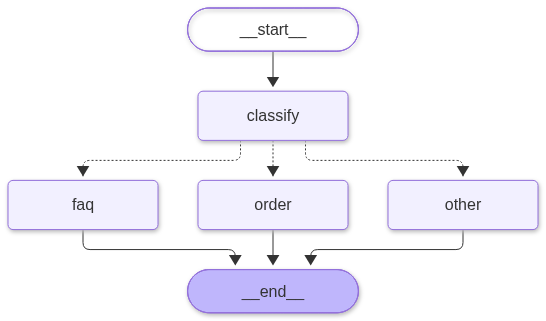

In [84]:
from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))

In [85]:
tests = [
    "What is the price of iPhone 15?",
    "I am Ravi. I want to order 2 iPhone 15 phones with 128GB storage for 24 December.",
    "Good morning!",
    "What are your store timings?",
    "Do orders require advance notice?"
]

for msg in tests:
    print("\nCustomer:", msg)

    try:
        for step in graph.stream(
            {"message": msg},
            stream_mode="updates"
        ):
            print("  ", step)

    except Exception as e:
        print("Error:", e)


Customer: What is the price of iPhone 15?
   {'classify': {'intent': 'faq'}}
   {'faq': {'reply': 'The iPhone\u202f15 costs **₹55,000**.'}}

Customer: I am Ravi. I want to order 2 iPhone 15 phones with 128GB storage for 24 December.
   {'classify': {'intent': 'order'}}
   {'order': {'reply': 'Order summary:\n- Name: Ravi  \n- Mobile model: iPhone\u202f15  \n- Quantity: 2  \n- Storage: 128\u202fGB  \n- Order date: 24\u202fDecember\u202f2026  \n- Total cost: ₹110,000  \n\nPlease confirm if you’d like to place this order.'}}

Customer: Good morning!
   {'classify': {'intent': 'other'}}
   {'other': {'reply': 'Hello! Welcome to Smart Mobile Store. I can help you with mobile prices, orders and store policies.'}}

Customer: What are your store timings?
   {'classify': {'intent': 'faq'}}
   {'faq': {'reply': 'Monday to Saturday: 9\u202fAM\u202f–\u202f8\u202fPM.  \nSunday: 10\u202fAM\u202f–\u202f6\u202fPM.'}}

Customer: Do orders require advance notice?
   {'classify': {'intent': 'faq'}}
   {

In [88]:
print("Orders before:", orders)

result = log_order.invoke({
    "name": "Ravi",
    "mobile_model": "iPhone 15",
    "qty": 2,
    "date": "2026-12-24",
    "storage": "128GB",
    "total": 110000
})

print(result)
print("Orders after:", orders)

Orders before: [{'name': 'Ravi', 'mobile_model': 'iPhone 15', 'qty': 2, 'date': '2026-12-24', 'storage': '128GB', 'total': 110000}]
Order saved successfully: {'name': 'Ravi', 'mobile_model': 'iPhone 15', 'qty': 2, 'date': '2026-12-24', 'storage': '128GB', 'total': 110000}
Orders after: [{'name': 'Ravi', 'mobile_model': 'iPhone 15', 'qty': 2, 'date': '2026-12-24', 'storage': '128GB', 'total': 110000}, {'name': 'Ravi', 'mobile_model': 'iPhone 15', 'qty': 2, 'date': '2026-12-24', 'storage': '128GB', 'total': 110000}]
